# Week 3: Supervised Machine Learning Models

In this assignment, I will use the Bank Marketing dataset to train KNN, Decision Tree, Logistic Regression, and Linear Regression models. I will compare the three classification models using accuracy, confusion matrices, precision, recall, and F1-score. I will also conduct a separate Linear Regression experiment using regression metrics and explain the results.

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests
import zipfile
import io

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score
)

sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


In [9]:
# Download the Bank Marketing dataset
url = "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"

response = requests.get(url, timeout=60)
response.raise_for_status()

# Open the outer ZIP file
with zipfile.ZipFile(io.BytesIO(response.content)) as outer_zip:

    print("Files in outer ZIP:", outer_zip.namelist())

    # Find the inner bank.zip file
    inner_zip_name = next(
        name for name in outer_zip.namelist()
        if name.endswith("bank.zip")
    )

    inner_zip_bytes = outer_zip.read(inner_zip_name)

# Open the inner ZIP file
with zipfile.ZipFile(io.BytesIO(inner_zip_bytes)) as inner_zip:

    # Find bank-full.csv
    csv_file = next(
        name for name in inner_zip.namelist()
        if name.endswith("bank-full.csv")
    )

    # Load the CSV file
    with inner_zip.open(csv_file) as file:
        df = pd.read_csv(file, sep=";")

print("\nDataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Files in outer ZIP: ['bank.zip', 'bank-additional.zip']

Dataset loaded successfully!
Dataset shape: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


## Step 1: Data Preparation

First, I will inspect the dataset, check its columns and data types, and identify missing values and duplicate rows before training the models.

In [10]:
# Display column names and data types
df.info()

# Display the first five rows
display(df.head())

# Check dataset dimensions
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


Rows: 45211
Columns: 17


In [11]:
# Check missing values
print("Missing values in each column:")
print(df.isnull().sum())

# Check duplicate rows
print("\nNumber of duplicate rows:", df.duplicated().sum())

Missing values in each column:
age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

Number of duplicate rows: 0


### 1.1 Data Cleaning

I will remove duplicate rows and treat the value `unknown` as missing information. I will fill missing values using statistics calculated from the training data to avoid data leakage.

In [12]:
# Remove duplicate rows
df = df.drop_duplicates().copy()

# Treat unknown values as missing
df = df.replace("unknown", np.nan)

print("Dataset shape after removing duplicates:", df.shape)

print("\nMissing values after treating unknown as missing:")
print(df.isnull().sum())

Dataset shape after removing duplicates: (45211, 17)

Missing values after treating unknown as missing:
age              0
job            288
marital          0
education     1857
default          0
balance          0
housing          0
loan             0
contact      13020
day              0
month            0
duration         0
campaign         0
pdays            0
previous         0
poutcome     36959
y                0
dtype: int64


### 1.2 Target Class Distribution

The target column is `y`. It indicates whether a customer subscribed to a term deposit. I will count each class and plot the distribution to check whether the dataset is balanced.

Target class counts:
y
no     39922
yes     5289
Name: count, dtype: int64

Target class percentages:
y
no     88.3
yes    11.7
Name: proportion, dtype: float64


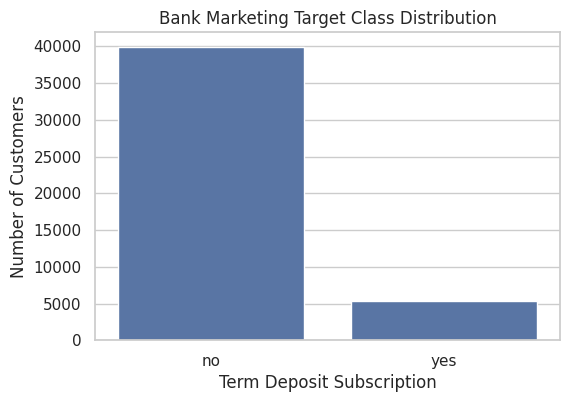

In [13]:
print("Target class counts:")
print(df["y"].value_counts())

print("\nTarget class percentages:")
print((df["y"].value_counts(normalize=True) * 100).round(2))

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="y")
plt.title("Bank Marketing Target Class Distribution")
plt.xlabel("Term Deposit Subscription")
plt.ylabel("Number of Customers")
plt.show()

The dataset is imbalanced because most customers did not subscribe to a term deposit. The number of customers who subscribed is much smaller. Therefore, I will use stratified splitting and evaluate the models using precision, recall, and F1-score as well as accuracy.

In [14]:
# Separate features and target
X = df.drop(columns=["y"])
y = df["y"]

# Split the data into 80% training and 20% testing
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("Training features:", X_train_raw.shape)
print("Testing features:", X_test_raw.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training features: (36168, 16)
Testing features: (9043, 16)

Training target distribution:
y
no     31937
yes     4231
Name: count, dtype: int64

Testing target distribution:
y
no     7985
yes    1058
Name: count, dtype: int64


### 1.4 Handle Missing Values and Encode Categorical Columns

Machine learning models need numerical input. I will fill missing numerical values with the training median and missing categorical values with the training mode. Then, I will convert text categories into numerical columns using one-hot encoding.

In [15]:
# Make copies of the training and testing data
X_train = X_train_raw.copy()
X_test = X_test_raw.copy()

# Identify numerical and categorical columns
numeric_cols = X_train.select_dtypes(include=np.number).columns
categorical_cols = X_train.select_dtypes(exclude=np.number).columns

# Fill numerical missing values using training medians
for col in numeric_cols:
    median_value = X_train[col].median()
    X_train[col] = X_train[col].fillna(median_value)
    X_test[col] = X_test[col].fillna(median_value)

# Fill categorical missing values using training modes
for col in categorical_cols:
    mode_value = X_train[col].mode()[0]
    X_train[col] = X_train[col].fillna(mode_value)
    X_test[col] = X_test[col].fillna(mode_value)

# Encode categorical columns
X_train = pd.get_dummies(X_train, drop_first=True, dtype=int)
X_test = pd.get_dummies(X_test, drop_first=True, dtype=int)

# Ensure both sets have exactly the same columns
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

print("Encoding completed!")
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Missing values in training data:", X_train.isnull().sum().sum())
print("Missing values in testing data:", X_test.isnull().sum().sum())

Encoding completed!
Training features: (36168, 38)
Testing features: (9043, 38)
Missing values in training data: 0
Missing values in testing data: 0


### 1.5 Feature Scaling

StandardScaler transforms numerical feature values to a common scale. I will fit the scaler on the training data only and use it to transform the testing data. This prevents data leakage.

In [16]:
# Create the scaler
scaler = StandardScaler()

# Fit and transform training data
X_train_scaled = scaler.fit_transform(X_train)

# Transform testing data without fitting again
X_test_scaled = scaler.transform(X_test)

print("Training data scaled:", X_train_scaled.shape)
print("Testing data scaled:", X_test_scaled.shape)

print("\nData preparation completed successfully!")

Training data scaled: (36168, 38)
Testing data scaled: (9043, 38)

Data preparation completed successfully!


## Step 2: K-Nearest Neighbors (KNN)

KNN predicts a customer's subscription outcome by comparing the customer with nearby data points. I will first train the model using 5 neighbors and then test different odd values of K from 1 to 15.

In [17]:
# Train KNN with 5 neighbors
knn_model = KNeighborsClassifier(n_neighbors=5)

knn_model.fit(X_train_scaled, y_train)

# Predict test results
knn_predictions = knn_model.predict(X_test_scaled)

# Calculate accuracy
knn_accuracy = accuracy_score(y_test, knn_predictions)

print("KNN Accuracy:", round(knn_accuracy, 4))

KNN Accuracy: 0.8928


### 2.1 Find the Best K Value

I will test odd values of K from 1 to 15. I will compare their test accuracies and select the K value that gives the highest accuracy.

In [18]:
# Test odd K values from 1 to 15
k_values = range(1, 16, 2)
knn_accuracies = []

for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train_scaled, y_train)

    predictions = model.predict(X_test_scaled)
    accuracy = accuracy_score(y_test, predictions)

    knn_accuracies.append(accuracy)

    print(f"K = {k}, Accuracy = {accuracy:.4f}")

# Find the best K
best_index = np.argmax(knn_accuracies)
best_k = list(k_values)[best_index]
best_accuracy = knn_accuracies[best_index]

print("\nBest K:", best_k)
print("Best Accuracy:", round(best_accuracy, 4))

K = 1, Accuracy = 0.8716
K = 3, Accuracy = 0.8873
K = 5, Accuracy = 0.8928
K = 7, Accuracy = 0.8963
K = 9, Accuracy = 0.8962
K = 11, Accuracy = 0.8970
K = 13, Accuracy = 0.8963
K = 15, Accuracy = 0.8962

Best K: 11
Best Accuracy: 0.897


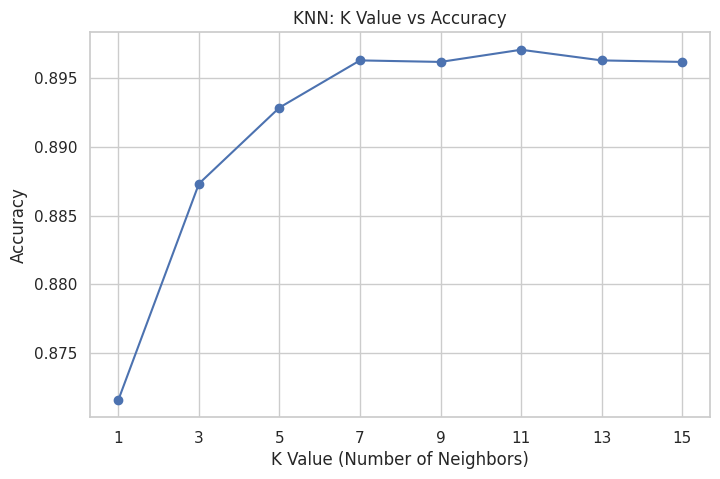

In [19]:
plt.figure(figsize=(8, 5))

plt.plot(
    list(k_values),
    knn_accuracies,
    marker="o"
)

plt.xlabel("K Value (Number of Neighbors)")
plt.ylabel("Accuracy")
plt.title("KNN: K Value vs Accuracy")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

The KNN model was tested using odd K values from 1 to 15. I compared their accuracies using a line plot. The best K value was 11, which achieved an accuracy of 89.70%. I will use this K value for the final KNN evaluation.

### 2.2 Final KNN Model

Based on my experiments, K = 11 achieved the highest accuracy of 89.70%. I will train the final KNN model using 11 neighbors and use it for the final model comparison.

In [20]:
# Train the final KNN model with the best K
knn_model = KNeighborsClassifier(n_neighbors=11)

knn_model.fit(X_train_scaled, y_train)

# Final KNN predictions
knn_predictions = knn_model.predict(X_test_scaled)

print("Final KNN Accuracy:",
      round(accuracy_score(y_test, knn_predictions), 4))

Final KNN Accuracy: 0.897


## Step 3: Decision Tree Classifier

A Decision Tree makes predictions using a series of decision rules. I will train a Decision Tree and test different maximum depths to understand how tree complexity affects accuracy.

In [21]:
# Test different maximum depths
depth_values = [2, 3, 5, 10, None]
tree_accuracies = []

for depth in depth_values:
    tree_model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    tree_model.fit(X_train, y_train)
    predictions = tree_model.predict(X_test)

    accuracy = accuracy_score(y_test, predictions)
    tree_accuracies.append(accuracy)

    print(f"Max Depth = {depth}, Accuracy = {accuracy:.4f}")

# Find the best depth
best_depth_index = np.argmax(tree_accuracies)
best_depth = depth_values[best_depth_index]
best_tree_accuracy = tree_accuracies[best_depth_index]

print("\nBest tree depth:", best_depth)
print("Best tree accuracy:", round(best_tree_accuracy, 4))

Max Depth = 2, Accuracy = 0.8947
Max Depth = 3, Accuracy = 0.8997
Max Depth = 5, Accuracy = 0.8996
Max Depth = 10, Accuracy = 0.8970
Max Depth = None, Accuracy = 0.8656

Best tree depth: 3
Best tree accuracy: 0.8997


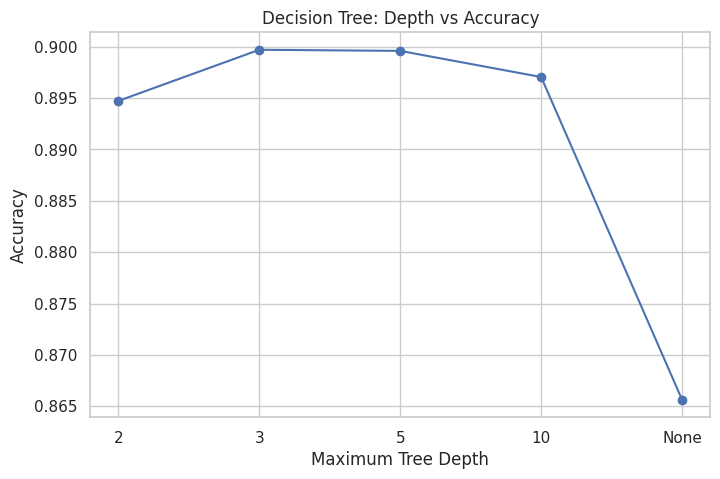

In [22]:
depth_labels = [str(depth) for depth in depth_values]

plt.figure(figsize=(8, 5))
plt.plot(depth_labels, tree_accuracies, marker="o")
plt.xlabel("Maximum Tree Depth")
plt.ylabel("Accuracy")
plt.title("Decision Tree: Depth vs Accuracy")
plt.grid(True)
plt.show()

The Decision Tree was tested with maximum depths of 2, 3, 5, 10, and None. A shallow tree may not learn enough patterns, while a very deep tree may overfit the training data by learning noise. I compared the test accuracies to identify the best depth for this dataset.

### 3.1 Final Decision Tree Model

The Decision Tree with a maximum depth of 3 achieved the highest test accuracy of 89.97%. I will use this depth for the final Decision Tree model.

In [23]:
# Train the final Decision Tree
tree_model = DecisionTreeClassifier(
    max_depth=3,
    random_state=42
)

tree_model.fit(X_train, y_train)

# Make predictions
tree_predictions = tree_model.predict(X_test)

print("Final Decision Tree Accuracy:",
      round(accuracy_score(y_test, tree_predictions), 4))

Final Decision Tree Accuracy: 0.8997


## Step 4: Logistic Regression

Logistic Regression predicts the probability that a customer belongs to a particular class. I will train the model and use predict_proba to display the predicted probabilities for five test customers.

In [24]:
# Train Logistic Regression
log_model = LogisticRegression(max_iter=1000)

log_model.fit(X_train_scaled, y_train)

# Predict test classes
log_predictions = log_model.predict(X_test_scaled)

print("Logistic Regression Accuracy:",
      round(accuracy_score(y_test, log_predictions), 4))

Logistic Regression Accuracy: 0.8993


In [25]:
# Get probabilities for the first five test rows
probabilities = log_model.predict_proba(X_test_scaled[:5])

probability_df = pd.DataFrame(
    probabilities,
    columns=log_model.classes_
)

print("Predicted probabilities for five test customers:")
display(probability_df)

print("Predicted classes:")
print(log_model.predict(X_test_scaled[:5]))

Predicted probabilities for five test customers:


,no,yes
0,0.983169,0.016831
1,0.977462,0.022538
2,0.971922,0.028078
3,0.989220,0.010780
4,0.962683,0.037317


Predicted classes:
['no' 'no' 'no' 'no' 'no']


## Step 4.1: Linear Regression

Linear Regression is mainly used to predict continuous numerical values. For this experiment, I will encode the target classes as 0 (`no`) and 1 (`yes`) and train a Linear Regression model. I will evaluate its numerical predictions using MAE, MSE, RMSE, and R². This is a supplementary experiment because Linear Regression is not specifically designed for classification.

In [ ]:
# Import regression evaluation metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Convert target classes into numerical values
y_train_numeric = y_train.map({"no": 0, "yes": 1})
y_test_numeric = y_test.map({"no": 0, "yes": 1})

# Train Linear Regression
linear_model = LinearRegression()
linear_model.fit(X_train_scaled, y_train_numeric)

# Predict numerical values
linear_predictions = linear_model.predict(X_test_scaled)

# Evaluate Linear Regression
mae = mean_absolute_error(y_test_numeric, linear_predictions)
mse = mean_squared_error(y_test_numeric, linear_predictions)
rmse = np.sqrt(mse)
r2 = r2_score(y_test_numeric, linear_predictions)

print("Linear Regression Results")
print("MAE:", round(mae, 4))
print("MSE:", round(mse, 4))
print("RMSE:", round(rmse, 4))
print("R² Score:", round(r2, 4))

## Step 5: Model Evaluation

I will evaluate the final KNN, Decision Tree, and Logistic Regression models using accuracy, confusion matrices, precision, recall, and F1-score. This will help me compare their overall performance and understand the types of prediction errors they make.

In [26]:
models = {
    "KNN": knn_predictions,
    "Decision Tree": tree_predictions,
    "Logistic Regression": log_predictions
}

for name, predictions in models.items():
    print("\n", "=" * 50)
    print(name)
    print("=" * 50)

    print("Accuracy:",
          round(accuracy_score(y_test, predictions), 4))

    print(classification_report(
        y_test,
        predictions,
        zero_division=0
    ))


KNN
Accuracy: 0.897
              precision    recall  f1-score   support

          no       0.91      0.98      0.94      7985
         yes       0.64      0.27      0.38      1058

    accuracy                           0.90      9043
   macro avg       0.78      0.63      0.66      9043
weighted avg       0.88      0.90      0.88      9043


Decision Tree
Accuracy: 0.8997
              precision    recall  f1-score   support

          no       0.92      0.97      0.94      7985
         yes       0.63      0.35      0.45      1058

    accuracy                           0.90      9043
   macro avg       0.77      0.66      0.70      9043
weighted avg       0.88      0.90      0.89      9043


Logistic Regression
Accuracy: 0.8993
              precision    recall  f1-score   support

          no       0.92      0.97      0.94      7985
         yes       0.63      0.33      0.43      1058

    accuracy                           0.90      9043
   macro avg       0.78      0.65    

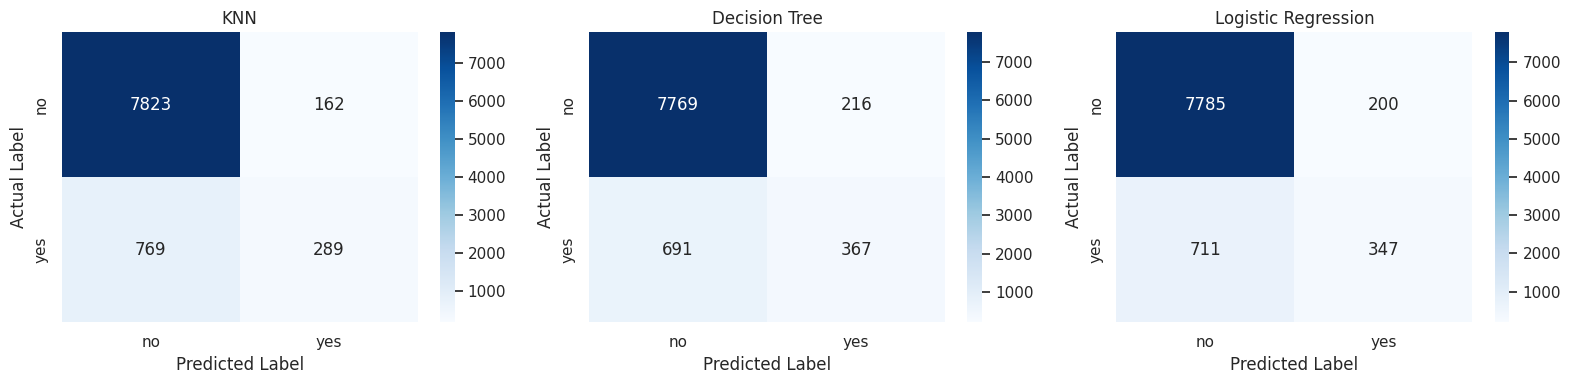

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, (name, predictions) in zip(axes, models.items()):
    cm = confusion_matrix(
        y_test,
        predictions,
        labels=["no", "yes"]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["no", "yes"],
        yticklabels=["no", "yes"],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

plt.tight_layout()
plt.show()

In [28]:
comparison_results = []

for name, predictions in models.items():
    comparison_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, pos_label="yes", zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, pos_label="yes", zero_division=0
        ),
        "F1": f1_score(
            y_test, predictions, pos_label="yes", zero_division=0
        )
    })

comparison_df = pd.DataFrame(comparison_results)

display(
    comparison_df.round(4).sort_values(
        by="F1", ascending=False
    ).reset_index(drop=True)
)

,Model,Accuracy,Precision,Recall,F1
0,Decision Tree,0.8997,0.6295,0.3469,0.4473
1,Logistic Regression,0.8993,0.6344,0.3280,0.4324
2,KNN,0.8970,0.6408,0.2732,0.3830


## Final Analysis

### 1. Best Model

Decision Tree performed best among the three classification models, with an accuracy of 89.97% and an F1-score of 0.4473. It also achieved the highest recall of 0.3469. This makes it the strongest overall choice based on our evaluation metrics. Logistic Regression achieved a similar accuracy of 89.93%, while KNN achieved 89.70%.

### 2. False Positives vs. False Negatives

A false positive occurs when the model predicts that a customer will subscribe, but the customer does not subscribe. A false negative occurs when the model predicts that a customer will not subscribe, but the customer actually subscribes.

In a marketing campaign, false positives can waste resources contacting customers who do not subscribe. False negatives can cause the business to miss potential customers. The importance of each error depends on the campaign's costs and goals.

### 3. Accuracy vs. F1-Score

The dataset is imbalanced because many more customers did not subscribe than subscribed. Therefore, accuracy alone does not fully describe model performance. The F1-score balances precision and recall for the positive class (`yes`). Decision Tree achieved the highest F1-score of 0.4473, but its recall of 0.3469 shows that it still misses many customers who actually subscribe.

### 4. Where Does the Best Model Make Mistakes?


The Decision Tree confusion matrix is:

| Actual / Predicted | Predicted No | Predicted Yes |
|---|---:|---:|
| Actual No | 7,769 | 216 |
| Actual Yes | 691 | 367 |

The model correctly identifies 7,769 customers who did not subscribe and 367 customers who subscribed. However, it incorrectly predicts subscription for 216 customers who did not subscribe (false positives). It also misses 691 actual subscribers (false negatives).

The model identifies only 367 out of 1,058 actual subscribers, which gives a recall of approximately 34.69%. Therefore, although the model achieves 89.97% accuracy, it could be improved to identify more potential subscribers.

### 5. Linear Regression

Linear Regression was included as a supplementary experiment by encoding the target variable as 0 (`no`) and 1 (`yes`). It was evaluated using regression metrics such as MAE, MSE, RMSE, and R². However, Linear Regression is primarily designed for predicting continuous numerical values, so Logistic Regression is more suitable for predicting binary outcomes.

### Which Metric Matters More for This Problem?

For a marketing campaign that aims to identify as many potential subscribers as possible, recall is important because a false negative means missing a customer who would have subscribed. However, if contacting customers is expensive, precision is also important because false positives can waste marketing resources. In this experiment, I would prioritize improving recall while monitoring precision.

### Conclusion

Among the three classification models tested, Decision Tree was the best overall according to the F1-score, recall, and accuracy. However, its relatively low recall indicates that further improvements may be needed to identify more potential subscribers.